In [ ]:
import pandas as pd
import numpy as np
import sys, os
sys.path.append(os.path.abspath('.'))
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, 
    recall_score, 
    f1_score, 
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
from itertools import product
from typing import Dict, Any, Optional
from preprocessor_funct import drop_by_correlation, impute_values, gscore, training_score, features_engenering, evaluate_model

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV

print("Imports ok")

Imports ok


In [254]:
# Charger les données d'entraînement
train_df = pd.read_csv('data/train.csv', delimiter=';')

print(f"Forme des données d'entraînement : {train_df.shape}")
print(f"Nombre d'échantillons (n) : {train_df.shape[0]}")
print(f"Nombre de caractéristiques (d) : {train_df.shape[1] - 1}")  # Soustraire 1 pour la colonne cible
print(f"Colonnes : {list(train_df.columns)}")
print("\nPremières lignes :")
print(train_df.head())

# Vérifier les types de données et informations de base
print("\nTypes de données et informations :")
print(train_df.info())

y = train_df['quality']
counts = y.value_counts().sort_index()
percent = (counts / counts.sum()* 100).round(2)

print("Distribution des classes (counts):")
print(counts)
print("\nPourcentages (%):")
print(percent)

Forme des données d'entraînement : (4469, 15)
Nombre d'échantillons (n) : 4469
Nombre de caractéristiques (d) : 14
Colonnes : ['id', 'beer_style', 'bitterness_IBU', 'diacetyl_concentration', 'lactic_acid', 'final_gravity', 'sodium', 'free_CO2', 'dissolved_oxygen', 'original_gravity', 'pH', 'gypsum_level', 'alcohol_ABV', 'fermentation_strength', 'quality']

Premières lignes :
   id beer_style  bitterness_IBU  diacetyl_concentration  lactic_acid  \
0   0       Pale           7.997                   0.446        0.280   
1   1       Pale           6.906                   0.222        0.303   
2   2      Brown           7.183                   0.636        0.071   
3   3       Pale           6.403                   0.242        0.260   
4   4      Brown           7.917                   0.182        0.347   

   final_gravity  sodium  free_CO2  dissolved_oxygen  original_gravity     pH  \
0         10.803   0.052    24.999           157.026             0.995  3.057   
1          6.305   0.

In [256]:
def visualize_distributions(df: pd.DataFrame) -> None:
    corr = df.corr(numeric_only=True).abs()
    sns.heatmap(corr, cmap='coolwarm', center=0)
    sns.pairplot(df[['lactic_acid','pH','alcohol_ABV','final_gravity','quality']], hue='quality')
    plt.figure(figsize=(10,6))
    sns.heatmap(df[['gravity_drop','acid_balance','gas_balance','quality']].corr(),
                annot=True, cmap='coolwarm', center=0)
    plt.title("Corrélations des nouvelles features avec la qualité")
    plt.show()

    corr2 = df[['acid_x_gas','log_gravity_drop','quality']].corr()
    sns.heatmap(corr2, annot=True, cmap='coolwarm', center=0)
    plt.title("Corrélations des features non linéaires avec la qualité")
    plt.show()


In [ ]:

def preprossesing_dataset(train_df: pd.DataFrame) -> tuple[pd.DataFrame, list, list]:
    """
    Cette fonction effectue le prétraitement complet du jeu de données d'entraînement.
    1. Conserve uniquement les classes de qualité comprises entre 4 et 8,les autres 
       classes sont rares ou absentes
    2. Crée de nouvelles features à partir des existantes.
    3. Impute les valeurs manquantes et corrige les incohérences.
    4. Supprime les variables peu pertinentes ou redondantes selon leur corrélation.

    Args:
    train_df : pd.DataFrame

    Return:
        df : DataFrame prétraité prêt 
        stats : statistiques sur l’imputation
        dropped_features : liste des variables supprimées
    """

    # Filtrage du dataset entre les classes 4 et 8
    df = train_df[train_df['quality'].between(4, 8)]

    # Visualisation des distributions et corrélations entre les variables et la qualité.
    # Veuillez decommenté pour voir.
    # visualize_distributions(df)

    # Création de nouvelles features dérivées des variables existantes
    df = features_engenering(df, is_train=True)

    # Imputation des valeurs manquantes et correction des valeurs incohérentes.
    df, stats = impute_values(df, is_train=True)

    # Suppression des variables redondantes ou peu corrélées avec la cible :
    # high_threshold : supprime les variables trop corrélées entre elles (> 0.95)
    # low_threshold : supprime les variables faiblement corrélées avec la cible (< 0.02)
    df, dropped_features = drop_by_correlation(
        df, 
        high_threshold=0.95, 
        low_threshold=0.02
    )

    return df, stats, dropped_features




In [ ]:

# Prétraitemetn des données 
df, stats, dropped_features = preprossesing_dataset(train_df)

# Assure la suppresion de la colonne 'id', car n'apporte aucune information
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# Séparation des features et de la cible 'quality'
X = df.drop(columns=['quality'])
y = df['quality']

# Division du jeu de données en ensembles d’entraînement et de validation
# test_size=0.2 : 20 % des données sont réservées pour la validation
# tratify=y : garantit que la distribution des classes est équilibrée entre les deux ensembles
# random_state=42 : permet la reproductibilité
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# categorical_features: contient les variables qualitatives à encoder
categorical_features = ['beer_style']
# numeric_features : contient les variables numériques à normaliser
numeric_features = [col for col in df.columns if col not in categorical_features + ['quality']]

# cat : applique un encodage One-Hot sur les variables catégorielles
# num : applique une normalisation sur les variables numériques
preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('num', StandardScaler(), numeric_features)
])


Features supprimées : ['pH']


Optimisation gradient boosting...
Accuracy: 0.6243
Recall Macro: 0.3819
F1 Macro: 0.3935

              precision    recall  f1-score   support

           4       0.40      0.09      0.14        23
           5       0.68      0.68      0.68       299
           6       0.61      0.72      0.66       397
           7       0.57      0.42      0.48       151
           8       0.00      0.00      0.00        19

    accuracy                           0.62       889
   macro avg       0.45      0.38      0.39       889
weighted avg       0.61      0.62      0.61       889



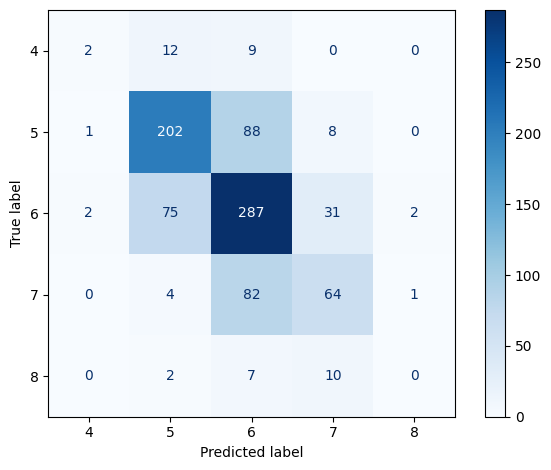

Meilleurs hyperparam RandomizedSearchCV :{'classifier__subsample': 1.0, 'classifier__n_estimators': 500, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 4, 'classifier__max_features': None, 'classifier__max_depth': 9, 'classifier__learning_rate': 0.1}
Meilleur score en CV: 0.38813696385778806
Accuracy sur validation: 0.6242969628796401
Recall macro sur validation: 0.38186095599607967


In [ ]:

print("Optimisation gradient boosting...")

# Création du pipeline pour le Gradient Boosting
# preprocessor : gère le prétraitement des données 
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42)) 
])

# Plan d'expérience pour recherche aléatoire
gb_hyperparam = {
    'classifier__n_estimators': [100, 200, 300, 500],       # Nombre d’arbres dans le modèle
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1],    
    'classifier__max_depth': [3, 5, 7, 9],                  
    'classifier__min_samples_split': [5, 10, 15, 20],     
    'classifier__min_samples_leaf': [1, 2, 4],              
    'classifier__subsample': [0.7, 0.8, 0.9, 1.0],         
    'classifier__max_features': ['sqrt', 'log2', None] 
}

# Recherche aléatoire d’hyperparamètres avec validation croisée
# n_iter : nombre de combinaisons testées
# scoring : rappel macro, car les classes sont
# n_jobs=-1 : utilise tous les cœurs CPU 
# random_state : garantit la reproductibilité des résultats
gb = RandomizedSearchCV(
    gb_pipeline,
    gb_hyperparam,
    n_iter=30,
    cv=5,
    scoring='recall_macro',
    n_jobs=-1,
    random_state=42
)

# Entraînement du modèle sur les données d’entraînement
gb.fit(X_train, y_train)
# Prédiction des classes sur les données de validation
y_pred_gb = gb.predict(X_val)

# Évaluation du modèle 
gscore(y_val, y_pred_gb, gb)
training_score(gb, y_val, y_pred_gb)



Optimisation regression logistique...


/Users/yamira.poldosilva/Documents/UDEM/A25/IFT3395/kaggle_1_25-10 copie 2/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Users/yamira.poldosilva/Documents/UDEM/A25/IFT3395/kaggle_1_25-10 copie 2/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Users/yamira.poldosilva/Documents/UDEM/A25/IFT3395/kaggle_1_25-10 copie 2/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Users/yamira.poldosilva/Documents/UDEM/A25/IFT3395/kaggle_1_25-10 copie 2/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'

Accuracy: 0.3645
Recall Macro: 0.4127
F1 Macro: 0.2943

              precision    recall  f1-score   support

           4       0.09      0.57      0.15        23
           5       0.58      0.51      0.54       299
           6       0.61      0.23      0.34       397
           7       0.33      0.38      0.36       151
           8       0.05      0.37      0.09        19

    accuracy                           0.36       889
   macro avg       0.33      0.41      0.29       889
weighted avg       0.52      0.36      0.40       889



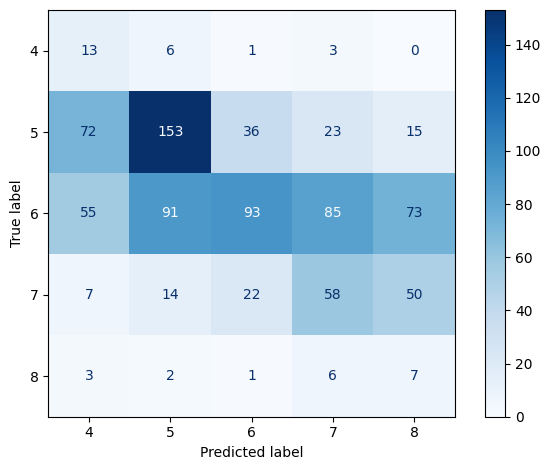

Meilleurs hyperparam RandomizedSearchCV :{'classifier__penalty': 'l2', 'classifier__l1_ratio': 0, 'classifier__C': 5}
Meilleur score en CV: 0.4400178972462666
Accuracy sur validation: 0.3644544431946007
Recall macro sur validation: 0.41274140335433945


In [ ]:

print("Optimisation regression logistique...")

# Création du pipeline pour la régression logistique
# 1. preprocessor : prétraitement des données 
# 2. scaler : normalisation des variables numériques
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler(with_mean=False)),
    ('classifier', LogisticRegression(
        solver='saga',
        max_iter=3000,
        random_state=42, # Permet la reproductibilité des résultats
        class_weight='balanced', # Permet de balancer les classes
    ))
])
# Plan d'expérience pour la recherche aléatoire
# - C : paramètre de régularisation 
lr_hyperparam = {
    'classifier__C': [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10],
    'classifier__penalty': ['l1', 'l2', 'elasticnet'],
    'classifier__l1_ratio': [0, 0.25, 0.5, 0.75, 1.0]
}

# Configuration de la recherche aléatoire d'hyperparamètres
# - n_iter : nombre de combinaisons testées aléatoirement
# - scoring : métrique utilisée pour évaluation
# - n_jobs=-1 : utilisation de tous les cœurs disponibles
lr = RandomizedSearchCV(
    lr_pipeline,
    lr_hyperparam,
    n_iter=20,
    cv=5,
    scoring='recall_macro',
    n_jobs=-1,
    random_state=42
)

# Entraînement du modèle sur les données d'entraînement
lr.fit(X_train, y_train)
# Prédiction sur les données de validation
y_pred_lr = lr.predict(X_val)

# Évaluation du modèle
gscore(y_val, y_pred_lr, lr)
training_score(lr, y_val, y_pred_lr)

Optimisation ExtraTrees...
Accuracy: 0.5444
Recall Macro: 0.4137
F1 Macro: 0.3890

              precision    recall  f1-score   support

           4       0.13      0.13      0.13        23
           5       0.61      0.69      0.65       299
           6       0.65      0.41      0.50       397
           7       0.41      0.74      0.53       151
           8       0.20      0.11      0.14        19

    accuracy                           0.54       889
   macro avg       0.40      0.41      0.39       889
weighted avg       0.57      0.54      0.54       889



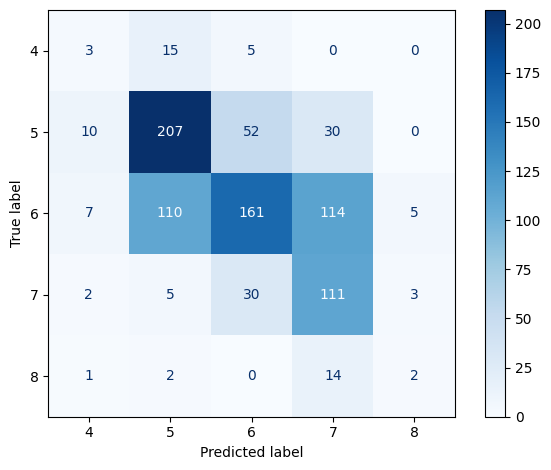

Meilleurs hyperparam RandomizedSearchCV :{'classifier__n_estimators': 200, 'classifier__min_samples_split': 20, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 0.75, 'classifier__max_depth': 20, 'classifier__criterion': 'gini', 'classifier__bootstrap': False}
Meilleur score en CV: 0.4708399877287512
Accuracy sur validation: 0.5444319460067492
Recall macro sur validation: 0.41372930645446304


In [ ]:
print("Optimisation ExtraTrees...")


# Création du pipeline pour le modèle Extra Trees
# preprocessor : applique le prétraitement
# scaler : normalisation des variables numériques 
et_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler(with_mean=False)),
    ('classifier', ExtraTreesClassifier(
        class_weight='balanced', # Balance les classes
        random_state=42,
        n_jobs=-1
    ))
])

# Plan d'expérience pour la recherche aléatoire des hyperparamètres
et_hyperparam = {
    'classifier__n_estimators': [200, 400, 800, 1200],
    'classifier__max_depth': [None, 10, 20, 30, 50],
    'classifier__max_features': ['sqrt', 'log2', 0.5, 0.75, 1.0],
    'classifier__min_samples_split': [2, 5, 10, 20],
    'classifier__min_samples_leaf': [1, 2, 4, 8],
    'classifier__bootstrap': [False, True],
    'classifier__criterion': ['gini', 'entropy']  
}
# Recherche aléatoire d’hyperparamètres (RandomizedSearchCV)
# n_iter: nombre de combinaisons testées
# - scoring : évaluation selon rappel macro 
# - n_jobs=-1 : Utilise tous les coeurs du CPU
et = RandomizedSearchCV(
    et_pipeline,
    et_hyperparam,
    n_iter=20,
    cv=5,
    scoring='recall_macro',
    n_jobs=-1,
    random_state=42
)
# Entraînement du modèle Extra Trees sur l'ensemble d’entraînement
et.fit(X_train, y_train)
# Prédiction sur l'ensemble de validation
y_pred_et = et.predict(X_val)

# Évaluation des performances du modèle
gscore(y_val, y_pred_et, et)
training_score(et, y_val, y_pred_et)


In [ ]:
# Dictionnaire contenant les meilleurs modèles entraînés pour chaque algorithme
models = {
    "GradientBoosting": gb.best_estimator_,
    "LogReg": lr.best_estimator_,
    "ExtraTrees": et.best_estimator_,
}
# Évaluation de chaque modèle sur le jeu de validation
score_table = pd.DataFrame({name: evaluate_model(m, X_val, y_val) for name, m in models.items()}).T
score_table.sort_values(by="Macro_Recall", ascending=False)


,Acc,Macro_Recall,Macro_F1,Macro_Precision
ExtraTrees,0.544432,0.413729,0.389013,0.400577
LogReg,0.364454,0.412741,0.294252,0.329880
GradientBoosting,0.624297,0.381861,0.393522,0.451577


In [539]:
# Calcul des probabilités de prédiction pour chaque modèle sur le jeu de validation
gb_proba = gb.best_estimator_.predict_proba(X_val)
lr_proba = lr.best_estimator_.predict_proba(X_val)
et_proba = et.best_estimator_.predict_proba(X_val)
# Extraction des classes cibles
classes = lr.best_estimator_.classes_

def weighted_voting(w):
    """
    Fonction qui pondére les probablités des modèles.
    Args:
        w: liste de trois poids (w_gb, w_lr, w_et)

    Returns: 
     array: Prédictions finales issues du vote pondéré.
    """
    # Si tous les poids sont nuls, on retourne les prédictions de la régression logistique
    if sum(w) == 0:
        return classes[lr_proba.argmax(1)]
    # Calcul de la moyenne pondérée des probabilités entre les trois modèles
    weights= (w[0]*gb_proba + w[1]*lr_proba + w[2]*et_proba) / sum(w)
    # On choisit pour chaque cas la classe ayant la probabilité maximale
    return classes[weights.argmax(1)]

# Poids à tester pour chaque modèle
w1s = np.linspace(1, 3, 3)
w2s = np.linspace(15, 20, 21)
w3s = np.linspace(0, 10, 21)

# Initialisation des valeurs à trouver
best_score, best_weights = -1, None

# Boucle sur toutes les combinaisons possibles de poids
for w in product(w1s, w2s, w3s):

    temp = weighted_voting(w)
    # Calcul de rappel macro pour évaluer la performance
    score = recall_score(y_val, temp, average='macro')
    
    if score > best_score:
        best_score, best_weights = score, w

print(f"Les poids optimales pour [gb, lr, et] sont: {best_weights}")

Les poids optimales pour [gb, lr, et] sont: (np.float64(3.0), np.float64(15.0), np.float64(9.0))


/Users/yamira.poldosilva/Documents/UDEM/A25/IFT3395/kaggle_1_25-10 copie 2/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


Accuracy: 0.5647
Recall Macro: 0.4519
F1 Macro: 0.4187

              precision    recall  f1-score   support

           4       0.17      0.35      0.23        23
           5       0.65      0.63      0.64       299
           6       0.64      0.54      0.58       397
           7       0.49      0.58      0.53       151
           8       0.09      0.16      0.11        19

    accuracy                           0.56       889
   macro avg       0.41      0.45      0.42       889
weighted avg       0.59      0.56      0.58       889



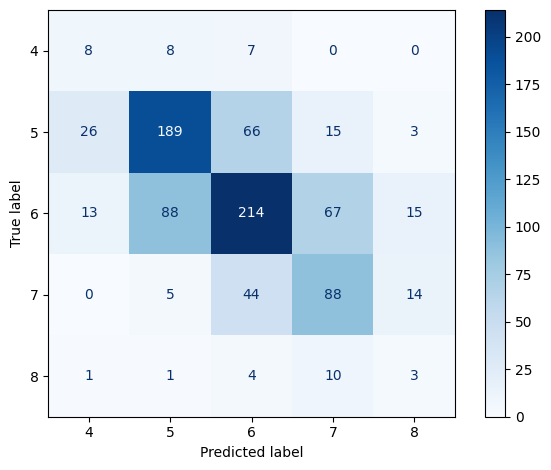

In [540]:


# Création d’un modèle d’ensemble (Voting Classifier) combinant plusieurs algorithmes
# Le vote se fait de manière *pondérée* selon les poids optimaux trouvés précédemment
voting_clf_final = VotingClassifier( 
    estimators=[
        ('gb', gb.best_estimator_),  
        ('lr', lr.best_estimator_),  
        ('et', et.best_estimator_),  
    ],
    voting='soft',        # moyenne pondérée des probabilités
    weights=best_weights, # Poids optimaux trouvés 
    n_jobs=-1             # Utilise tous les cœurs CPU 
)

# Entraînement du classifieur combiné sur le jeu de données d’entraînement
voting_clf_final.fit(X_train, y_train)

# Prédiction des classes sur le jeu de validation
y_pred_final = voting_clf_final.predict(X_val)

# Évaluation du modèle final
gscore(y_val, y_pred_final, voting_clf_final)



In [541]:

def get_best_weights(pp, classes):
    """
    Recherche des poids optimaux à appliquer aux probabilités des classes 4 et 8 pour améliorer macro recall
    args: 
        pp : Tableau des probabilités prédites pour chaque classe
        classes : Tableau contenant les étiquettes des classes correspondantes
    Returns:
        tuple :
            (w4, w8), les poids optimaux pour les classes 4 et 8.
    """
    # Les poids à tester 
    ws = np.linspace(1.6, 1.9, 9)
    # Initisiation des valeurs à tester
    best_score, best_weights = -1, (0.0, 0.0)

    # Boucle sur toutes les combinaisons
    for w4, w8 in product(ws, ws):
        
        a = pp.copy()
        # Application des poids 
        a[:, classes == 4] *= w4
        a[:, classes == 8] *= w8

        # Prédiction de la classe la plus probable après ajustement
        y_pred = classes[a.argmax(1)]
    
        macro_recall = recall_score(y_val, y_pred, average="macro")
        # Si le score est meilleur que le précédent, on met à jour les poids
        if macro_recall > best_score:
            best_score, best_weights = macro_recall, (w4,w8)


    w4, w8 = best_weights
    print(f"Les poids optimales pour [w4, w8] sont {best_weights}")
    # Retourne les deux poids optimisés
    return w4, w8

Les poids optimales pour [w4, w8] sont (np.float64(1.75), np.float64(1.6))
Accuracy: 0.4589
Recall Macro: 0.4807
F1 Macro: 0.3667

              precision    recall  f1-score   support

           4       0.09      0.57      0.15        23
           5       0.67      0.53      0.59       299
           6       0.63      0.42      0.50       397
           7       0.50      0.42      0.46       151
           8       0.08      0.47      0.14        19

    accuracy                           0.46       889
   macro avg       0.39      0.48      0.37       889
weighted avg       0.59      0.46      0.51       889



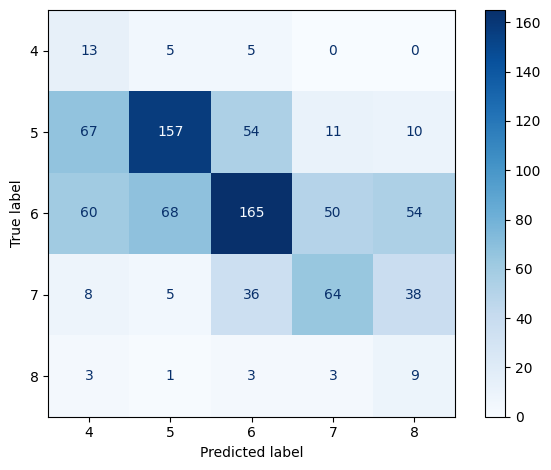

In [542]:
# Calcule des probabilités prédites par le modèle d’ensemble
proba = voting_clf_final.predict_proba(X_val).copy()

# Récupération des classes cibles
classes = voting_clf_final.classes_

# Recherche des meilleurs poids à appliquer pour les classes 4 et 8
w4, w8 = get_best_weights(proba,classes)

# Ajustement des probabilités prédites
proba[:, classes == 4] *= w4
proba[:, classes == 8] *= w8

# Calcul de la classe finale prédite
y_pred_final = classes[proba.argmax(1)]

# Évaluation finale du modèle
gscore(y_val, y_pred_final, voting_clf_final)


In [543]:
# Charger test data
test_df = pd.read_csv("data/test.csv", sep=";")

test_ids = test_df['id'].copy()

# Application du prétraitement sur l'ensemble de test
test_df = features_engenering(test_df, is_train=False)
test_df, _ = impute_values(test_df, is_train=False, stats=stats)
test_df = test_df.drop(columns=dropped_features, errors='ignore')

train_features = X.columns.tolist()

# Valider que les ensembles d'entrainement et test ont les mêmes colonnes
missing_cols = set(train_features) - set(test_df.columns)
extra_cols = set(test_df.columns) - set(train_features)

for col in missing_cols:
    test_df[col] = 0

test_df = test_df.drop(columns=list(extra_cols), errors='ignore')

X_test = test_df[train_features].copy()

assert X_test.shape[1] == X.shape[1], "Différence colonnes train/test"

# Prédiction des probabilités de chaque classe pour le jeu de test
proba_test = voting_clf_final.predict_proba(X_test)
# Récupération de la liste des classes dans le modèle
classes = voting_clf_final.classes_
# Application des poids optimaux trouvés
proba_test[:, classes == 4] *= w4
proba_test[:, classes == 8] *= w8

proba_test /= proba_test.sum(1, keepdims=True)

# Prédiction finale
y_pred = classes[proba_test.argmax(axis=1)]

print("Distribution finale :")
print(pd.Series(y_pred).value_counts().sort_index())





Distribution finale :
4    115
5    113
6     94
7     96
8     93
Name: count, dtype: int64


In [544]:
# Création du DataFrame de soumission 
submission = pd.DataFrame({
    'id': test_ids,
    'quality': y_pred.astype(int)
})
# Nom du fichier de soumission CSV
filename = "ift3395_YAPS_MCS_V64.csv"
submission.to_csv(filename, index=False)

# Comparaison entre deux versions de soumissions pour vérifier les changements
df1 = pd.read_csv("ift3395_YAPS_MCS_V61.csv")
df2 = pd.read_csv(filename)

comparison = df1.compare(df2)
print(comparison)
print("Nombre de différences :", len(comparison))

Empty DataFrame
Columns: []
Index: []
Nombre de différences : 0
